# Tutorial 08a: CNNs for image classification

Before using convolutions for traffic grids, we will study them in their most familiar setting: handwritten digit classification. A small, balanced MNIST subset keeps the experiment fast enough to inspect filters, tune the network, and examine mistakes.

The central idea is **weight sharing**: the same small filter scans every image location, allowing a pattern learned in one place to be recognized elsewhere.

## Open this notebook

- **Colab.** Open the notebook, then run the setup cell below before any data-loading cell. It clones the public course repository and changes into `08 Convolutional neural networks`, so relative data paths work.
- **On your own computer.** Open the notebook from its lesson folder so the data files sit beside it.


In [ ]:
from pathlib import Path
import os

def in_colab():
    try:
        import google.colab  # noqa: F401
        return True
    except ImportError:
        return False

if in_colab():
    print("Running in Google Colab")
    REPO_URL = "https://github.com/hku-kejintao/AI-Code.git"
    LESSON_DIR = "08 Convolutional neural networks"
    base = Path("/content")
    repo = base / "AI-Code"
    os.chdir(base)
    if not repo.exists():
        !git clone {REPO_URL}
    lesson_path = repo / LESSON_DIR
    if not lesson_path.exists():
        raise FileNotFoundError(f"Lesson folder not found: {lesson_path}")
    os.chdir(lesson_path)
else:
    print("Running on your own computer")

print("Current folder:", os.getcwd())


### Check the packages

The cell should print version numbers and the word `ready`. NumPy holds arrays, pandas holds tables, Matplotlib draws figures, and scikit-learn provides preprocessing, models, and metrics. PyTorch builds the neural networks used in this lesson.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import torch

print("numpy", np.__version__)
print("pandas", pd.__version__)
print("matplotlib", plt.matplotlib.__version__)
print("scikit-learn", sklearn.__version__)
print("torch", torch.__version__)
print("ready")


### Install, only if the check failed

Skip this cell when the check printed `ready`. After installation finishes, restart the kernel and run the cells above again.


In [ ]:
%pip install numpy pandas matplotlib scikit-learn torch


In [1]:
DATA_FILE="mnist_small.npz"

## Open the notebook

In [2]:
from pathlib import Path
if not Path(DATA_FILE).exists():
    !git clone -q https://github.com/JinTaoKe/AI-Code.git
    %cd "AI-Code/08 Convolutional neural networks"

In [3]:
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from IPython.display import display

plt.style.use("seaborn-v0_8-whitegrid")
np.random.seed(42); torch.manual_seed(42); torch.set_num_threads(2)
DEVICE="cuda" if torch.cuda.is_available() else "cpu"
print("device:",DEVICE)

device: cpu


## 1. Inspect images, labels, and shapes

Never send an array into a neural network before you can explain every dimension. MNIST images are 28 × 28 grayscale arrays; labels are integers from 0 to 9.

x_train: (6000, 28, 28) y_train: (6000,)
x_valid: (1000, 28, 28) y_valid: (1000,)
x_test : (1000, 28, 28) y_test : (1000,)
Each x is a 28 × 28 image; each y is one digit label.
pixel range: 0 255


,count
0,600
1,600
2,600
3,600
4,600
5,600
6,600
7,600
8,600
9,600


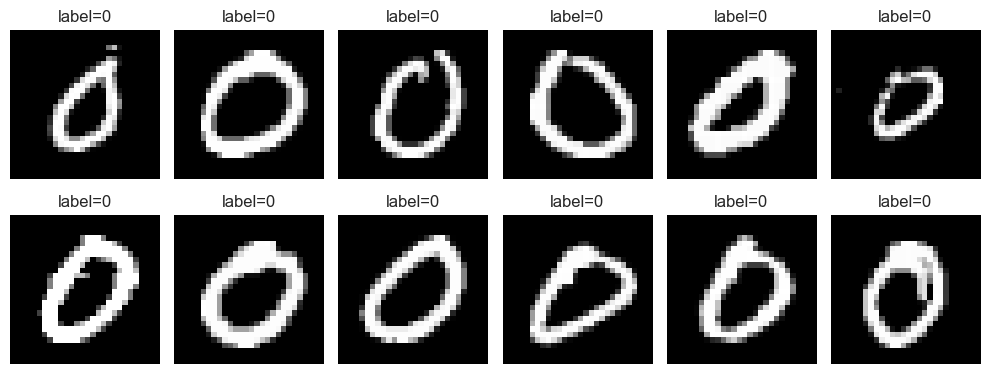

In [4]:
data=np.load(DATA_FILE)
x_train,y_train=data["x_train"],data["y_train"]
x_valid,y_valid=data["x_valid"],data["y_valid"]
x_test,y_test=data["x_test"],data["y_test"]
print("x_train:", x_train.shape, "y_train:", y_train.shape)
print("x_valid:", x_valid.shape, "y_valid:", y_valid.shape)
print("x_test :", x_test.shape, "y_test :", y_test.shape)
print("Each x is a 28 × 28 image; each y is one digit label.")
print("pixel range:",x_train.min(),x_train.max())
display(pd.Series(y_train).value_counts().sort_index().rename("count").to_frame())

fig,axes=plt.subplots(2,6,figsize=(10,4))
for ax,image,label in zip(axes.flat,x_train[:12],y_train[:12]):
    ax.imshow(image,cmap="gray"); ax.set_title(f"label={label}"); ax.axis("off")
plt.tight_layout()

## 2. Prepare channel-first tensors

PyTorch convolution expects `(batch, channels, height, width)`. We add a one-channel dimension and scale pixels from 0–255 to 0–1.

In [ ]:
x_train = (x_train[:, None] / 255).astype("float32")
x_valid = (x_valid[:, None] / 255).astype("float32")
x_test = (x_test[:, None] / 255).astype("float32")
print("After adding the grayscale channel dimension:")
print("x_train:", x_train.shape, "y_train:", y_train.shape)
print("x_valid:", x_valid.shape, "y_valid:", y_valid.shape)
print("x_test :", x_test.shape, "y_test :", y_test.shape)
print("Each x has dimensions: samples × 1 grayscale channel × 28 rows × 28 columns.")
print("The CNN uses pixels divided by 255; input range:", x_train.min(), "to", x_train.max())
print("This is an internal optimisation scale. Accuracy is still the percentage of correctly classified digits.")
train_loader=DataLoader(TensorDataset(torch.tensor(x_train),torch.tensor(y_train,dtype=torch.long)),batch_size=128,shuffle=True)
valid_loader=DataLoader(TensorDataset(torch.tensor(x_valid),torch.tensor(y_valid,dtype=torch.long)),batch_size=256)

## 3. Follow the spatial dimensions

Convolution with padding preserves height and width; max pooling halves them. After two pooling layers, 28 × 28 becomes 7 × 7.

In [6]:
class DigitCNN(nn.Module):
    def __init__(self, channels=8, dropout=0.15):
        super().__init__()
        self.features=nn.Sequential(
            nn.Conv2d(1,channels,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),
            nn.Conv2d(channels,2*channels,3,padding=1),nn.ReLU(),nn.MaxPool2d(2))
        self.classifier=nn.Sequential(nn.Flatten(),nn.Linear(2*channels*7*7,64),nn.ReLU(),nn.Dropout(dropout),nn.Linear(64,10))
    def forward(self,x): return self.classifier(self.features(x))

In [7]:
model=DigitCNN(channels=8).to(DEVICE)
print(model)
with torch.no_grad():
    sample=torch.tensor(x_train[:4]).to(DEVICE)
    features=model.features(sample)
    output=model(sample)
print("input:",tuple(sample.shape),"features:",tuple(features.shape),"logits:",tuple(output.shape))
print("trainable parameters:",sum(p.numel() for p in model.parameters()))

DigitCNN(
  (features): Sequential(
    (0): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=64, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.15, inplace=False)
    (4): Linear(in_features=64, out_features=10, bias=True)
  )
)
input: (4, 1, 28, 28) features: (4, 16, 7, 7) logits: (4, 10)
trainable parameters: 52138


## 4. Train and use validation accuracy

The validation set is for model selection. The test set remains untouched until the architecture and training choices are fixed.

In [ ]:
def train_classifier(model, train_loader, valid_loader, epochs=5, lr=1e-3):
    optimizer=torch.optim.Adam(model.parameters(),lr=lr)
    loss_fn=nn.CrossEntropyLoss(); history={"train_loss":[],"valid_accuracy":[]}
    best_state,best_accuracy=None,-1
    for epoch in range(epochs):
        model.train(); total_loss=0
        for xb,yb in train_loader:
            xb,yb=xb.to(DEVICE),yb.to(DEVICE)
            optimizer.zero_grad(); loss=loss_fn(model(xb),yb); loss.backward(); optimizer.step()
            total_loss+=loss.item()*len(xb)
        model.eval(); correct=total=0
        with torch.no_grad():
            for xb,yb in valid_loader:
                pred=model(xb.to(DEVICE)).argmax(1).cpu(); correct+=(pred==yb).sum().item(); total+=len(yb)
        accuracy=correct/total; history["train_loss"].append(total_loss/len(train_loader.dataset)); history["valid_accuracy"].append(accuracy)
        if accuracy>best_accuracy: best_accuracy,best_state=accuracy,copy.deepcopy(model.state_dict())
        print(f"epoch {epoch+1:02d} | training cross-entropy {history['train_loss'][-1]:.4f} | validation accuracy {accuracy:.3f}")
    model.load_state_dict(best_state); return history

def class_predictions(model,X,batch_size=256):
    model.eval(); output=[]
    with torch.no_grad():
        for (xb,) in DataLoader(TensorDataset(torch.tensor(X)),batch_size=batch_size):
            output.append(model(xb.to(DEVICE)).argmax(1).cpu().numpy())
    return np.concatenate(output)

In [ ]:
history=train_classifier(model,train_loader,valid_loader,epochs=5)
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].plot(history["train_loss"],marker="o"); axes[0].set(title="Training loss",xlabel="Epoch")
axes[1].plot(history["valid_accuracy"],marker="o"); axes[1].set(title="Validation accuracy",xlabel="Epoch",ylim=(0.7,1.0))
plt.tight_layout()

## 5. Open the black box a little

The first row shows learned 3 × 3 filters. The remaining rows show their activation maps for one digit. Bright areas are locations where a filter responds strongly.

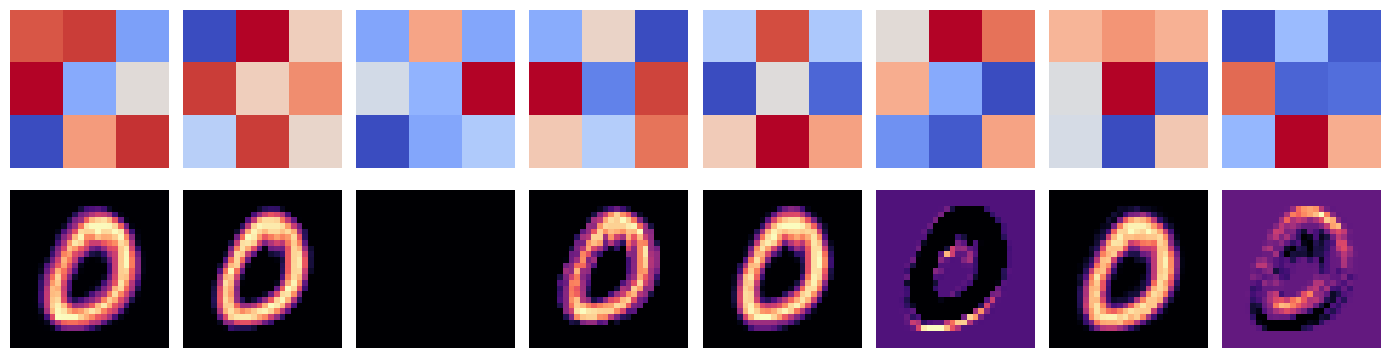

In [10]:
with torch.no_grad():
    filters=model.features[0].weight.cpu().numpy()[:,0]
    activations=torch.relu(model.features[0](torch.tensor(x_test[:1]).to(DEVICE))).cpu().numpy()[0]
fig,axes=plt.subplots(2,len(filters),figsize=(14,4))
for i in range(len(filters)):
    axes[0,i].imshow(filters[i],cmap="coolwarm"); axes[0,i].axis("off")
    axes[1,i].imshow(activations[i],cmap="magma"); axes[1,i].axis("off")
axes[0,0].set_ylabel("filter"); axes[1,0].set_ylabel("activation"); plt.tight_layout()

## 6. Final test evaluation after validation tuning

Validation accuracy fixes the CNN architecture, learning rate, regularisation, and epoch. The frozen CNN is now evaluated on the test images once. If several model families had been tuned, every family's final configuration—not only the validation winner—would be included in this test table.

test accuracy: 0.93


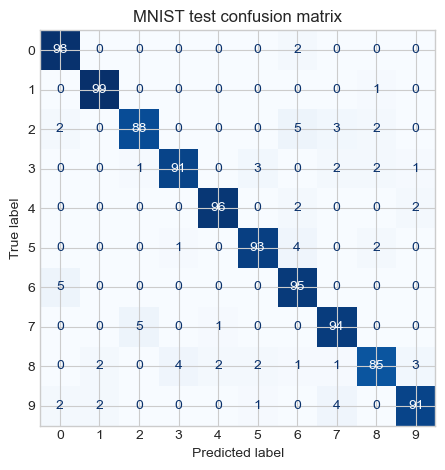

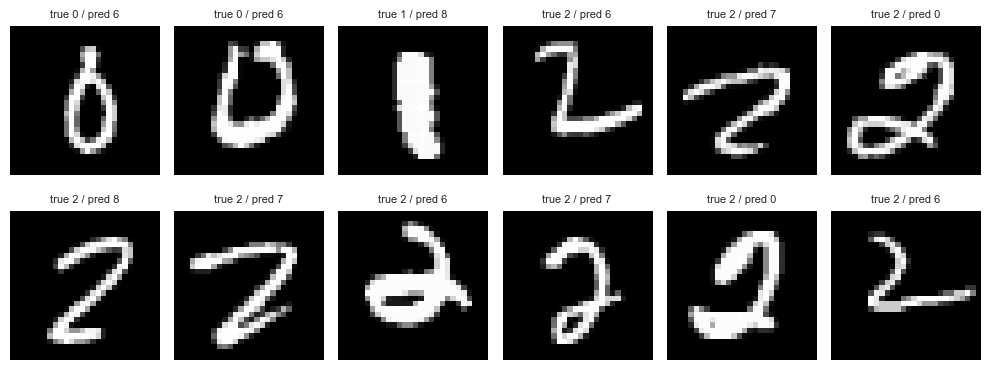

In [11]:
from sklearn.metrics import ConfusionMatrixDisplay,accuracy_score
test_pred=class_predictions(model,x_test)
print("test accuracy:",round(accuracy_score(y_test,test_pred),4))
ConfusionMatrixDisplay.from_predictions(y_test,test_pred,cmap="Blues",colorbar=False)
plt.title("MNIST test confusion matrix"); plt.tight_layout()

wrong=np.flatnonzero(test_pred!=y_test)[:12]
fig,axes=plt.subplots(2,6,figsize=(10,4))
for ax,i in zip(axes.flat,wrong):
    ax.imshow(x_test[i,0],cmap="gray"); ax.set_title(f"true {y_test[i]} / pred {test_pred[i]}",fontsize=8); ax.axis("off")
plt.tight_layout()

## What to remember

- Preserve spatial structure instead of flattening too early.
- Track shape changes through every convolution and pooling operation.
- Tune channels, depth, learning rate, batch size, and regularization on validation data.
- Use confusion matrices and example errors to understand performance.
- A small dataset is enough to learn the workflow, not enough to settle every design choice.